In [2]:
import numpy as np, pandas as pd, sklearn, matplotlib
print("numpy", np.__version__)
print("pandas", pd.__version__)
print("sklearn", sklearn.__version__)
print("Setup OK")

numpy 2.2.6
pandas 2.3.3
sklearn 1.7.2
Setup OK


Imports

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.width", 120)

Load and inspect the data

In [4]:
df = pd.read_csv("lab_ticket_resolution.csv")

print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nDescriptive statistics:")
display(df.describe(include="all"))

print("\nMissing values per column:")
print(df.isna().sum())

print("\nFirst five rows:")
display(df.head())

Shape: (240, 6)

Data types:
ticket_id                 object
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

Descriptive statistics:


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
count,240,240.000000,240.000000,240.000000,240.000000,240.000000
unique,240,NaN,NaN,NaN,NaN,NaN
top,T0001,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN
mean,NaN,5.491667,54.820833,6.105417,0.233333,19.361125
std,NaN,2.979697,26.145017,3.391426,0.423836,10.035058
min,NaN,1.000000,1.000000,0.500000,0.000000,0.500000
25%,NaN,3.000000,33.000000,3.300000,0.000000,11.015000
50%,NaN,5.500000,54.000000,5.800000,0.000000,19.610000
75%,NaN,8.000000,74.000000,9.200000,0.000000,27.122500



Missing values per column:
ticket_id                0
complexity_score         0
lines_changed            0
team_experience_years    0
reopened                 0
resolution_hours         0
dtype: int64

First five rows:


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


## Task 1: Data inspection

- **Shape:** 240 rows × 6 columns. This is a small dataset, so test metrics will be noisy and cross-validation matters.
- **Types:** `ticket_id` is a string (identifier); all other columns are numeric. `reopened` is a 0/1 integer.
- **Missing values:** none in any column. The `NaN` entries in `describe(include="all")` only mean a statistic doesn't apply to that column type.
- **Ranges:** `complexity_score` is 1–10 and `reopened` is only 0/1, as documented. No impossible values.
- **Target:** `resolution_hours` has mean ≈ 19.36 and median ≈ 19.61, so it is roughly symmetric. Std ≈ 10.0 hours, so the mean baseline will be off by about 10 hours on average.
- **Reopened rate:** about 23% of tickets.

In [5]:
target = "resolution_hours"

# Features available at the intended prediction time (ticket arrival)
features = ["complexity_score", "team_experience_years"]

# Excluded columns, kept for reference
excluded = {
    "ticket_id": "identifier, no predictive meaning",
    "lines_changed": "only known after the fix is done (leakage)",
    "reopened": "only known after resolution (leakage)",
}

X = df[features]
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features used:", features)

X shape: (240, 2)
y shape: (240,)
Features used: ['complexity_score', 'team_experience_years']


## Task 2: Target, features, and exclusions

**Intended use:** estimate resolution time at the moment a ticket arrives.

| Column | Known at ticket arrival? | Decision |
|---|---|---|
| `ticket_id` | Yes, but it is only a label | **Exclude** (identifier, no predictive meaning) |
| `complexity_score` | Yes, estimated at triage | **Keep** |
| `team_experience_years` | Yes, known for the assigned team | **Keep** |
| `lines_changed` | No, only known after the fix is written | **Exclude** (leakage) |
| `reopened` | No, can only happen after resolution | **Exclude** (leakage) |

Using `lines_changed` or `reopened` would let the model use information from the future, which inflates lab metrics but makes the model unusable in practice.

## Task 3: Train/test split

80/20 random split with `random_state=42` for reproducibility. The test set is not used to choose any model settings; hyperparameters are selected with cross-validation on the training set only.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (192, 2)
X_test:  (48, 2)
y_train: (192,)
y_test:  (48,)


Sanity check that the split looks similar

In [7]:
print("Train target mean/std:", round(y_train.mean(), 2), round(y_train.std(), 2))
print("Test target mean/std: ", round(y_test.mean(), 2), round(y_test.std(), 2))

Train target mean/std: 19.06 9.89
Test target mean/std:  20.58 10.6


Set up the cross-validation

In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

A reusable metrics helper

In [9]:
def evaluate(model, X_tr, y_tr, X_te, y_te, name):
    """Fit on train, score on test, return a dict of metrics."""
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    return {
        "model": name,
        "MAE": mean_absolute_error(y_te, pred),
        "RMSE": np.sqrt(mean_squared_error(y_te, pred)),
        "R2": r2_score(y_te, pred),
    }

results = []   # we'll keep appending to this list

Dummy baseline

In [10]:
dummy = DummyRegressor(strategy="mean")
results.append(evaluate(dummy, X_train, y_train, X_test, y_test, "Dummy (mean)"))
print(pd.DataFrame(results).round(3))

          model    MAE    RMSE     R2
0  Dummy (mean)  9.114  10.598 -0.021


Linear Regression

In [11]:
lin = LinearRegression()
results.append(evaluate(lin, X_train, y_train, X_test, y_test, "Linear"))

print(pd.DataFrame(results).round(3))
print("\nIntercept:", round(lin.intercept_, 3))
for f, c in zip(features, lin.coef_):
    print(f"Coefficient for {f}: {c:.3f}")

          model    MAE    RMSE     R2
0  Dummy (mean)  9.114  10.598 -0.021
1        Linear  2.906   3.572  0.884

Intercept: 4.249
Coefficient for complexity_score: 3.080
Coefficient for team_experience_years: -0.318


## Tasks 4 and 5: Baseline and linear regression

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Dummy (mean) | 9.114 | 10.598 | -0.021 |
| Linear | 2.906 | 3.572 | 0.884 |

- The Dummy model predicts the training mean for every ticket. Its slightly negative R² occurs because the test mean (20.58) differs from the training mean (19.06).
- Linear regression cut MAE from 9.1 to 2.9 hours and explains about 88% of the variance, using only features available at ticket arrival.
- Coefficients: each complexity point adds about 3.08 hours; each year of team experience reduces the time by about 0.32 hours.

## Task 6: Polynomial features

Pipelines of `PolynomialFeatures` → `StandardScaler` → `LinearRegression`, compared at degrees 1 (reference), 2, and 3 with 5-fold cross-validation on the training set only. The test set is not used for this comparison.

In [12]:
cv_rows = []
for degree in [1, 2, 3]:
    pipe = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
    mae = -cross_val_score(pipe, X_train, y_train, cv=cv,
                           scoring="neg_mean_absolute_error")
    rmse = -cross_val_score(pipe, X_train, y_train, cv=cv,
                            scoring="neg_root_mean_squared_error")
    r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    cv_rows.append({
        "degree": degree,
        "CV MAE": mae.mean(), "MAE std": mae.std(),
        "CV RMSE": rmse.mean(), "CV R2": r2.mean(),
    })

cv_df = pd.DataFrame(cv_rows)
print(cv_df.round(3))

   degree  CV MAE  MAE std  CV RMSE  CV R2
0       1   3.168    0.323    3.909  0.838
1       2   3.131    0.310    3.832  0.844
2       3   3.162    0.188    3.877  0.841


Compare train fit vs. Validation fit (overfitting evidence)

In [13]:
gap_rows = []
for degree in [1, 2, 3]:
    pipe = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
    pipe.fit(X_train, y_train)
    train_mae = mean_absolute_error(y_train, pipe.predict(X_train))
    cv_mae = -cross_val_score(pipe, X_train, y_train, cv=cv,
                              scoring="neg_mean_absolute_error").mean()
    gap_rows.append({"degree": degree, "train MAE": train_mae,
                     "CV MAE": cv_mae, "gap": cv_mae - train_mae})

print(pd.DataFrame(gap_rows).round(3))

   degree  train MAE  CV MAE    gap
0       1      3.127   3.168  0.041
1       2      3.063   3.131  0.068
2       3      3.007   3.162  0.155


Fit the polynomial models on train and score on test

In [14]:
for degree in [2, 3]:
    pipe = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
    results.append(evaluate(pipe, X_train, y_train, X_test, y_test,
                            f"Poly deg {degree}"))

print(pd.DataFrame(results).round(3))

          model    MAE    RMSE     R2
0  Dummy (mean)  9.114  10.598 -0.021
1        Linear  2.906   3.572  0.884
2    Poly deg 2  3.020   3.741  0.873
3    Poly deg 3  3.140   3.949  0.858


## Task 6 results: polynomial features

| Degree | CV MAE | CV RMSE | CV R² | Train MAE | Gap (CV - train) |
|---|---|---|---|---|---|
| 1 | 3.168 | 3.909 | 0.838 | 3.127 | 0.041 |
| 2 | 3.131 | 3.832 | 0.844 | 3.063 | 0.068 |
| 3 | 3.162 | 3.877 | 0.841 | 3.007 | 0.155 |

- Degree 2 has the best CV scores, but its improvement over degree 1 (about 0.04 hours MAE) is far smaller than the fold-to-fold standard deviation (about 0.3), so it is not meaningful.
- **Overfitting evidence:** training MAE falls steadily with degree, while CV MAE does not. The gap between them grows from 0.041 to 0.155, which indicates degree 3 is fitting noise.
- On the held-out test set, performance worsens as degree increases (MAE 2.906 → 3.020 → 3.140), consistent with the relationship being essentially linear.
- **Conclusion:** polynomial terms did not meaningfully improve generalization; the simpler linear model is preferred.

## Task 7: Ridge and Lasso

Pipelines of `PolynomialFeatures` → `StandardScaler` → `Ridge`/`Lasso`. Alpha is chosen with `GridSearchCV` (5-fold, training set only) over a log-spaced grid. Tested at degree 1 and degree 3 to see whether regularization can tame the overfitting seen in Task 6.

In [15]:
alphas = np.logspace(-3, 2, 30)   # 0.001 to 100

searches = {}
for degree in [1, 3]:
    for name, Model in [("Ridge", Ridge), ("Lasso", Lasso)]:
        pipe = make_pipeline(
            PolynomialFeatures(degree=degree, include_bias=False),
            StandardScaler(),
            Model(max_iter=20000)
        )
        gs = GridSearchCV(
            pipe,
            param_grid={f"{name.lower()}__alpha": alphas},
            cv=cv,
            scoring="neg_mean_absolute_error",
        )
        gs.fit(X_train, y_train)
        searches[(name, degree)] = gs
        print(f"{name} deg {degree}: best alpha = {gs.best_params_[f'{name.lower()}__alpha']:.4f}, "
              f"CV MAE = {-gs.best_score_:.3f}")

Ridge deg 1: best alpha = 0.0010, CV MAE = 3.168
Lasso deg 1: best alpha = 0.0010, CV MAE = 3.168
Ridge deg 3: best alpha = 6.2102, CV MAE = 3.143
Lasso deg 3: best alpha = 0.0356, CV MAE = 3.128


In [16]:
for (name, degree), gs in searches.items():
    best = gs.best_estimator_      # already refit on the full training set
    pred = best.predict(X_test)
    results.append({
        "model": f"{name} deg {degree} (alpha={gs.best_params_[f'{name.lower()}__alpha']:.3f})",
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

print(pd.DataFrame(results).round(3))

                       model    MAE    RMSE     R2
0               Dummy (mean)  9.114  10.598 -0.021
1                     Linear  2.906   3.572  0.884
2                 Poly deg 2  3.020   3.741  0.873
3                 Poly deg 3  3.140   3.949  0.858
4  Ridge deg 1 (alpha=0.001)  2.906   3.572  0.884
5  Lasso deg 1 (alpha=0.001)  2.906   3.572  0.884
6  Ridge deg 3 (alpha=6.210)  2.996   3.693  0.876
7  Lasso deg 3 (alpha=0.036)  2.979   3.696  0.876


In [17]:
feat_names = (PolynomialFeatures(degree=3, include_bias=False)
              .fit(X_train).get_feature_names_out(features))

# Plain degree 3 for comparison
plain3 = make_pipeline(PolynomialFeatures(degree=3, include_bias=False),
                       StandardScaler(), LinearRegression()).fit(X_train, y_train)

coef_table = pd.DataFrame({
    "Linear deg 3": plain3[-1].coef_,
    "Ridge deg 3": searches[("Ridge", 3)].best_estimator_[-1].coef_,
    "Lasso deg 3": searches[("Lasso", 3)].best_estimator_[-1].coef_,
}, index=feat_names)

print(coef_table.round(3))
print("\nSum of |coefficients|:")
print(coef_table.abs().sum().round(3))
print("\nLasso coefficients that are exactly zero:",
      int((coef_table["Lasso deg 3"] == 0).sum()), "of", len(coef_table))

                                          Linear deg 3  Ridge deg 3  Lasso deg 3
complexity_score                                 2.505        4.966        6.146
team_experience_years                           -7.722       -0.799       -0.507
complexity_score^2                              14.044        3.170        3.458
complexity_score team_experience_years          -2.151        0.333       -0.830
team_experience_years^2                         19.330        0.071       -0.000
complexity_score^3                              -6.644        1.164        0.000
complexity_score^2 team_experience_years         0.082       -0.607       -0.000
complexity_score team_experience_years^2         0.794       -0.151       -0.000
team_experience_years^3                        -12.303       -0.226       -0.049

Sum of |coefficients|:
Linear deg 3    65.575
Ridge deg 3     11.488
Lasso deg 3     10.990
dtype: float64

Lasso coefficients that are exactly zero: 4 of 9


## Task 7 results: Ridge and Lasso

Alpha selected by 5-fold CV on the training set (grid 0.001 to 100):

| Model | Best alpha | CV MAE | Test MAE | Test RMSE | Test R² |
|---|---|---|---|---|---|
| Ridge deg 1 | 0.001 | 3.168 | 2.906 | 3.572 | 0.884 |
| Lasso deg 1 | 0.001 | 3.168 | 2.906 | 3.572 | 0.884 |
| Ridge deg 3 | 6.210 | 3.143 | 2.996 | 3.693 | 0.876 |
| Lasso deg 3 | 0.036 | 3.128 | 2.979 | 3.696 | 0.876 |

- **Degree 1:** the CV picked the smallest alpha, so regularization had no effect. With 2 features and 192 rows there is nothing to overfit.
- **Degree 3:** regularization recovered much of the performance lost to overfitting (test MAE 3.140 to about 2.98), but did not beat plain linear regression (2.906).
- **Coefficients (degree 3, scaled features):** sum of absolute values fell from 65.6 (unregularized) to 11.5 (Ridge) and 11.0 (Lasso). The unregularized model used large, offsetting coefficients (e.g. +19.3 and -12.3 on experience terms), a sign of overfitting. Ridge shrank all coefficients smoothly; Lasso set 4 of 9 exactly to zero, keeping mainly low-order terms.
- **Why scaling:** the penalty depends on coefficient size, so features must share a common scale or the penalty would be applied unevenly.
- **Conclusion:** regularization stabilizes flexible models, but the underlying relationship is nearly linear, so the simple model remains the best choice.

## Task 8: Observed vs. predicted and residual plots

Plots use the held-out test set for two models: plain Linear regression and Lasso degree 3. I look for curvature, changing spread, and influential outliers.

In [18]:
models_to_plot = {
    "Linear": lin,
    "Lasso deg 3": searches[("Lasso", 3)].best_estimator_,
}

preds = {name: m.predict(X_test) for name, m in models_to_plot.items()}

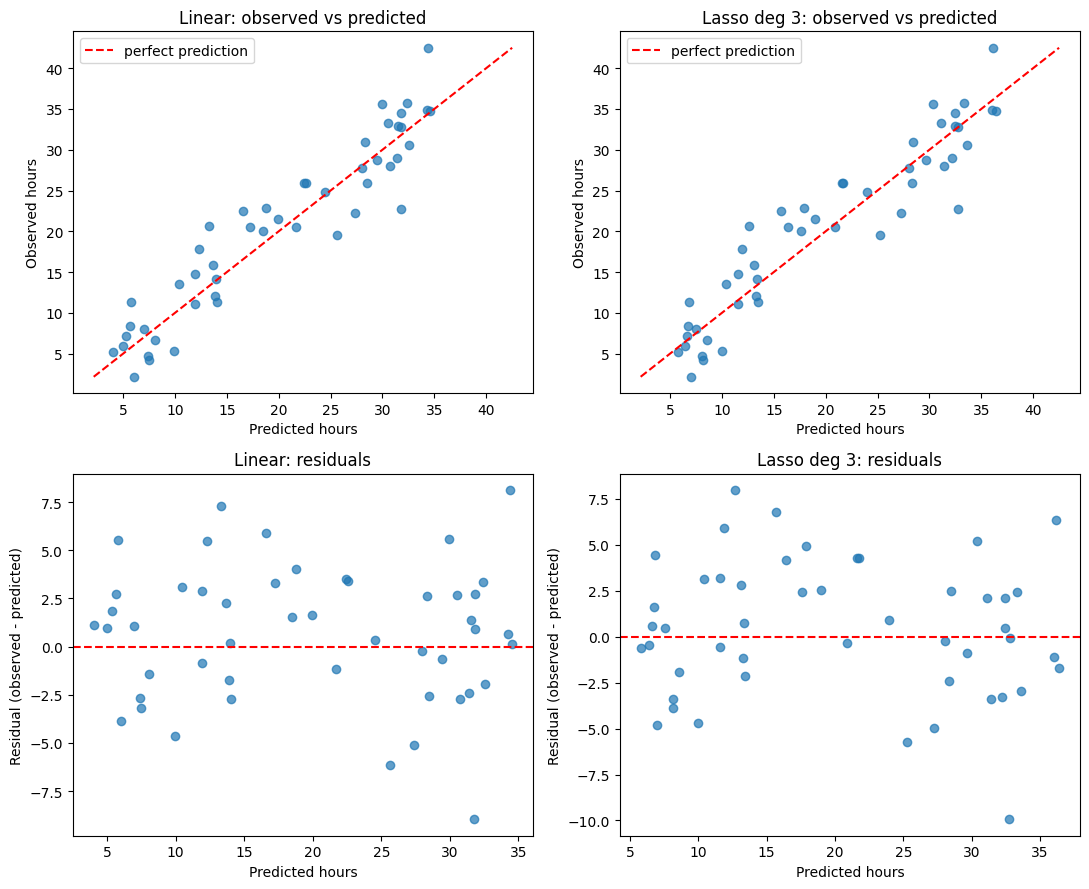

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

lo, hi = y_test.min(), y_test.max()

for col, (name, pred) in enumerate(preds.items()):
    resid = y_test - pred

    # Top row: observed vs predicted
    ax = axes[0, col]
    ax.scatter(pred, y_test, alpha=0.7)
    ax.plot([lo, hi], [lo, hi], "r--", label="perfect prediction")
    ax.set_title(f"{name}: observed vs predicted")
    ax.set_xlabel("Predicted hours")
    ax.set_ylabel("Observed hours")
    ax.legend()

    # Bottom row: residuals
    ax = axes[1, col]
    ax.scatter(pred, resid, alpha=0.7)
    ax.axhline(0, color="r", linestyle="--")
    ax.set_title(f"{name}: residuals")
    ax.set_xlabel("Predicted hours")
    ax.set_ylabel("Residual (observed - predicted)")

plt.tight_layout()
plt.savefig("diagnostic_plots.png", dpi=150)
plt.show()

In [22]:
for name, pred in preds.items():
    resid = y_test - pred
    cut = np.median(pred)
    low = resid[pred < cut].std()
    high = resid[pred >= cut].std()
    print(f"{name}:")
    print(f"  mean residual:  {resid.mean():.3f}")
    print(f"  residual std:   {resid.std():.3f}")
    print(f"  largest |resid|: {resid.abs().max():.3f}")
    print(f"  resid std, lower half of predictions: {low:.3f}")
    print(f"  resid std, upper half of predictions: {high:.3f}")

Linear:
  mean residual:  0.699
  residual std:   3.540
  largest |resid|: 8.966
  resid std, lower half of predictions: 3.297
  resid std, upper half of predictions: 3.776
Lasso deg 3:
  mean residual:  0.452
  residual std:   3.707
  largest |resid|: 9.936
  resid std, lower half of predictions: 3.602
  resid std, upper half of predictions: 3.784


## Task 8 results: diagnostics

Plots for Linear and Lasso degree 3 on the held-out test set (`diagnostic_plots.png`).

| | Mean residual | Residual std | Largest abs. residual | Std (lower half) | Std (upper half) |
|---|---|---|---|---|---|
| Linear | 0.699 | 3.540 | 8.966 | 3.297 | 3.776 |
| Lasso deg 3 | 0.452 | 3.707 | 9.936 | 3.602 | 3.784 |

- **Observed vs. predicted:** points follow the diagonal for both models with no systematic bend, so the straight line captures the relationship. Lasso deg 3 is slightly more scattered.
- **Curvature:** no U-shape or wave in either residual plot, so there is no evidence of missed nonlinearity.
- **Changing spread:** residual spread is roughly constant; upper-half std is only about 5 to 15% larger than lower-half. This is a mild effect, but it should be re-checked on more data.
- **Outliers:** one ticket is overpredicted by about 9 to 10 hours in both models. It is not extreme enough to be considered an influential outlier, but it contributes to RMSE exceeding MAE.
- **Bias:** a small positive mean residual (0.5 to 0.7 hours) is consistent with the test set having a higher average resolution time (20.58) than the training set (19.06).
- **Conclusion:** diagnostics give no reason to prefer the more flexible model.